### Bước 1: Chuẩn bị thư viện và tải dữ liệu MNIST

In [1]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow.keras.datasets import mnist
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from scipy.stats import mode
import warnings
warnings.filterwarnings('ignore')

# 1. Đọc bộ dữ liệu MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

print("Kích thước train_images ban đầu:", train_images.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Kích thước train_images ban đầu: (60000, 28, 28)


### Bước 2: Tiền xử lý và chuẩn hóa dữ liệu



In [2]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Chuẩn hóa giá trị pixel về [0, 1]
train_images_normalized = train_images / 255.0
test_images_normalized = test_images / 255.0

# Flatten ảnh từ (60000, 28, 28) thành (60000, 784)
X_train = train_images_normalized.reshape(len(train_images), -1)
X_test = test_images_normalized.reshape(len(test_images), -1)

print("Kích thước X_train sau khi flatten:", X_train.shape)

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Kích thước X_train sau khi flatten: (60000, 784)


### Bước 3: Thực hiện gom cụm bằng thuật toán $k$-Means

Vì tập MNIST có 10 chữ số khác nhau (từ 0 đến 9), ta sẽ chọn số cụm n_clusters = 10.

In [3]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Khởi tạo và huấn luyện KMeans với n_clusters = 10
# (Lưu ý: n_init='auto' hoặc 10 để tránh cảnh báo)
kmeans = KMeans(n_clusters=10, init='random', n_init=10, random_state=42)
kmeans.fit(X_train)

# Lấy nhãn cụm do KMeans dự đoán cho tập train
clusters = kmeans.labels_

print("Đã hoàn thành gom cụm k-Means với 10 cụm!")

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Đã hoàn thành gom cụm k-Means với 10 cụm!


### Bước 4: So sánh kết quả gom cụm với nhãn lớp có sẵn


In [4]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

# Hàm ánh xạ nhãn cụm sang nhãn thực tế
def infer_cluster_labels(kmeans_labels, true_labels):
    inferred_labels = np.zeros_like(kmeans_labels)
    for i in range(10):
        # Xác định các index thuộc cụm i
        vectorized_idx = (kmeans_labels == i)
        if np.any(vectorized_idx):
            # Tìm nhãn thực tế xuất hiện nhiều nhất trong cụm i
            modes = mode(true_labels[vectorized_idx], keepdims=True)
            # Dùng mode.mode[0] để lấy giá trị phổ biến nhất
            inferred_labels[vectorized_idx] = modes.mode[0]
    return inferred_labels

# Ánh xạ nhãn dự đoán từ k-Means
inferred_train_labels = infer_cluster_labels(clusters, train_labels)

# Tính độ chính xác (Accuracy) sau khi ánh xạ
acc = accuracy_score(train_labels, inferred_train_labels)
print(f"Độ chính xác tương đồng giữa cụm k-Means và nhãn thực tế: {acc * 100:.2f}%")

# In báo cáo chi tiết (Precision, Recall, F1-score)
print("\nClassification Report:")
print(classification_report(train_labels, inferred_train_labels))

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------
Độ chính xác tương đồng giữa cụm k-Means và nhãn thực tế: 58.26%

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.73      0.82      5923
           1       0.64      0.99      0.78      6742
           2       0.92      0.70      0.79      5958
           3       0.52      0.63      0.57      6131
           4       0.36      0.55      0.43      5842
           5       0.00      0.00      0.00      5421
           6       0.56      0.93      0.70      5918
           7       0.44      0.60      0.51      6265
           8       0.60      0.60      0.60      5851
           9       0.00      0.00      0.00      5949

    accuracy                           0.58     60000
   macro avg       0.50      0.57      0.52     60000
weighted avg       0.50      0.58      0.53     60000



### Bước 5: Hiển thị Confusion Matrix bằng Heatmap so sánh

Họ và tên: Lưu Đình Nghĩa
Mã sinh viên: 6451071051
------------------------------


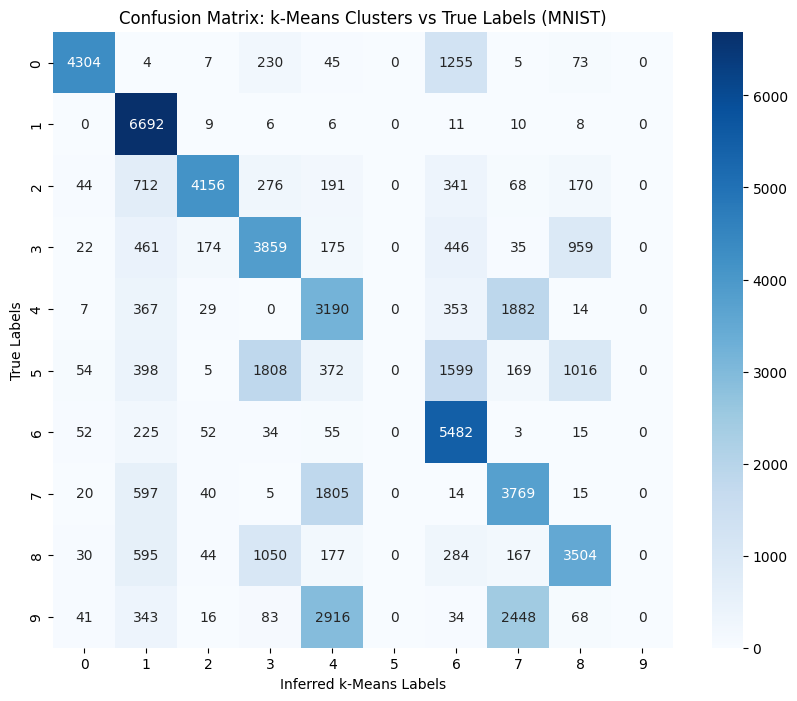

In [5]:
# In thông tin sinh viên
print("Họ và tên: Lưu Đình Nghĩa")
print("Mã sinh viên: 6451071051")
print("-" * 30)

cm = confusion_matrix(train_labels, inferred_train_labels)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=range(10), yticklabels=range(10))
plt.title("Confusion Matrix: k-Means Clusters vs True Labels (MNIST)")
plt.xlabel("Inferred k-Means Labels")
plt.ylabel("True Labels")
plt.show()